# IDM_sim: Intelligent Driver Model simulation

A simple simulation of one follower behind a lead vehicle, written so that it extends to a platoon by changing one number.

**Model.** The states are the space gap $s$ (bumper to bumper) and the follower speed $v$. The relative speed is $\Delta v = v_{lead} - v$, which is negative when the follower is closing in.

$$\frac{ds}{dt} = \Delta v \qquad (1)$$

$$\frac{dv}{dt} = a\left[1 - \left(\frac{v}{v_0}\right)^{\delta} - \left(\frac{s^*(v,\Delta v)}{s}\right)^{2}\right] \qquad (2)$$

$$s^*(v,\Delta v) = s_0 + \max\!\left(0,\; vT - \frac{v\,\Delta v}{2\sqrt{ab}}\right) \qquad (3)$$

Defaults are the typical values in Table I of Treiber, Hennecke and Helbing, *Phys. Rev. E* 62, 1805 (2000). The $\max(0,\cdot)$ floor keeps $s^*\ge s_0$ when the leader pulls away fast. It is in Treiber's simulation page but not in the 2000 paper. Integration is explicit Euler. **No braking limit is applied**, so a follower that is too close can brake harder than a real car could, and gaps can reach zero in extreme scenarios.

In [33]:
import numpy as np
import matplotlib.pyplot as plt

## 1 Parameters

In [34]:
# IDM parameters: Treiber, Hennecke & Helbing (2000), Table I ("typical values")
idm_params = {
    'v0': 120 / 3.6,   # desired speed (m/s), 120 km/h
    'T': 1.6,          # desired time gap (s)
    's0': 2.0,         # standstill gap (m)
    'a': 0.73,         # maximum acceleration (m/s^2)
    'b': 1.67,         # comfortable braking (m/s^2)
    'delta': 4.0,      # acceleration exponent (-)
}

# HELPER, not part of the IDM: it only lets us START the simulation at an equilibrium.
# Any other initial gap works too; the follower then just settles first.
def equilibrium_gap(speed, p):
    """Gap at which a follower at `speed`, behind a lead vehicle at the same speed, has zero acceleration (dv/dt = 0)."""
    return (p['s0'] + p['T'] * speed) / np.sqrt(1 - (speed / p['v0']) ** p['delta'])

## 2 The model and the simulation loop

`calculate_acceleration` is Eq. (2) with the reference gap $s^*$ from Eq. (3). `simulate_car_following` is the same Euler loop as in the homework: it takes the lead vehicle's speed history as input and returns the follower's gap and speed history.

In [35]:
def calculate_acceleration(ego_speed, space_gap, relative_speed, p):
    """
    IDM acceleration of the ego (following) vehicle.

    Parameters:
    - ego_speed: speed of the ego vehicle (m/s).
    - space_gap: bumper-to-bumper gap to the lead vehicle (m).
    - relative_speed: lead speed minus ego speed, delta v (m/s); negative when closing.
    - p: dictionary of IDM parameters.

    Returns:
    - Acceleration of the ego vehicle (m/s^2).
    """
    # Reference gap s*(v, dv): standstill gap + time-gap part + closing part, floored at s0
    closing_part = -ego_speed * relative_speed / (2 * np.sqrt(p['a'] * p['b']))
    s_star = p['s0'] + max(0.0, ego_speed * p['T'] + closing_part)

    free_road = 1 - (ego_speed / p['v0']) ** p['delta']
    interaction = (s_star / max(space_gap, 1e-3)) ** 2   # guard against dividing by zero at contact
    return p['a'] * (free_road - interaction)


def simulate_car_following(time_steps, p, initial_ego_speed, initial_space_gap, lead_speeds):
    """
    Simulate one follower behind a lead vehicle using Euler's method.

    Parameters:
    - time_steps: array of time steps (s).
    - p: dictionary of IDM parameters.
    - initial_ego_speed: initial speed of the ego vehicle (m/s).
    - initial_space_gap: initial space gap to the lead vehicle (m).
    - lead_speeds: speed profile of the lead vehicle, same length as time_steps (m/s).

    Returns:
    - time_steps, space_gaps (m), ego_speeds (m/s), lead_speeds (m/s).
    """
    dt = time_steps[1] - time_steps[0]
    space_gaps = [initial_space_gap]
    ego_speeds = [initial_ego_speed]

    for step in range(1, len(time_steps)):
        gap = space_gaps[-1]
        ego = ego_speeds[-1]
        lead = lead_speeds[step - 1]
        relative_speed = lead - ego                        # delta v = v_lead - v

        acceleration = calculate_acceleration(ego, gap, relative_speed, p)

        ego_speeds.append(max(0.0, ego + dt * acceleration))   # cars do not reverse
        space_gaps.append(gap + dt * relative_speed)

    return time_steps, space_gaps, ego_speeds, lead_speeds

In [36]:
def plot_cars(time_steps, all_speeds, all_space_gaps, title):
    """Speeds, space gaps and relative speeds. all_speeds[0] is the lead vehicle; all_space_gaps[i-1] belongs to vehicle i."""
    fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
    for i, speeds in enumerate(all_speeds):
        axes[0].plot(time_steps, speeds, label='Lead vehicle' if i == 0 else f'Vehicle {i}')
    axes[0].set_ylabel('Speed (m/s)')
    axes[0].set_title(title)

    for i, gaps in enumerate(all_space_gaps, start=1):
        axes[1].plot(time_steps, gaps, label=f'Vehicle {i}')
    axes[1].axhline(0, color='k', lw=1, ls='--', label='Collision (gap = 0)')
    axes[1].set_ylabel('Space gap (m)')

    for i in range(1, len(all_speeds)):
        rel = np.asarray(all_speeds[i - 1]) - np.asarray(all_speeds[i])
        axes[2].plot(time_steps, rel, label=f'Vehicle {i}')
    axes[2].axhline(0, color='k', lw=0.8)
    axes[2].set_ylabel(r'Relative speed $\Delta v$ (m/s)')
    axes[2].set_xlabel('Time (s)')

    for ax in axes:
        ax.legend(loc='upper right', fontsize=9)
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 3 Run: one follower

Lead speed $v_{lead}(t) = 10 + \sin(0.1\,t)$ m/s (mean 10 m/s, amplitude 1 m/s, period $2\pi/0.1 \approx 63$ s), $\Delta T = 0.1$ s, 2500 s. The follower starts at 10 m/s in its equilibrium gap for that speed, 18.1 m (from the `equilibrium_gap` helper, which is not part of the model), so any motion comes from the leader.

In [37]:
dt = 0.1                                           # time step (s)
total_time = 500.0                                # total simulation time (s), long enough to settle
time_steps = np.arange(0, total_time, dt)
lead_speeds = 10.0 + 1.0 * np.sin(0.1 * time_steps)   # lead vehicle speed profile (m/s): mean 10, amplitude 1, omega 0.1 rad/s

initial_ego_speed = 10.0                           # m/s, equal to the leader's mean speed
initial_space_gap = equilibrium_gap(initial_ego_speed, idm_params)   # steady-state gap (m)


print(f'Initial gap (steady state at {initial_ego_speed:.0f} m/s): {initial_space_gap:.1f} m')

time_steps, space_gaps, ego_speeds, lead_speeds = simulate_car_following(
    time_steps, idm_params, initial_ego_speed, initial_space_gap, lead_speeds)

Initial gap (steady state at 10 m/s): 18.1 m


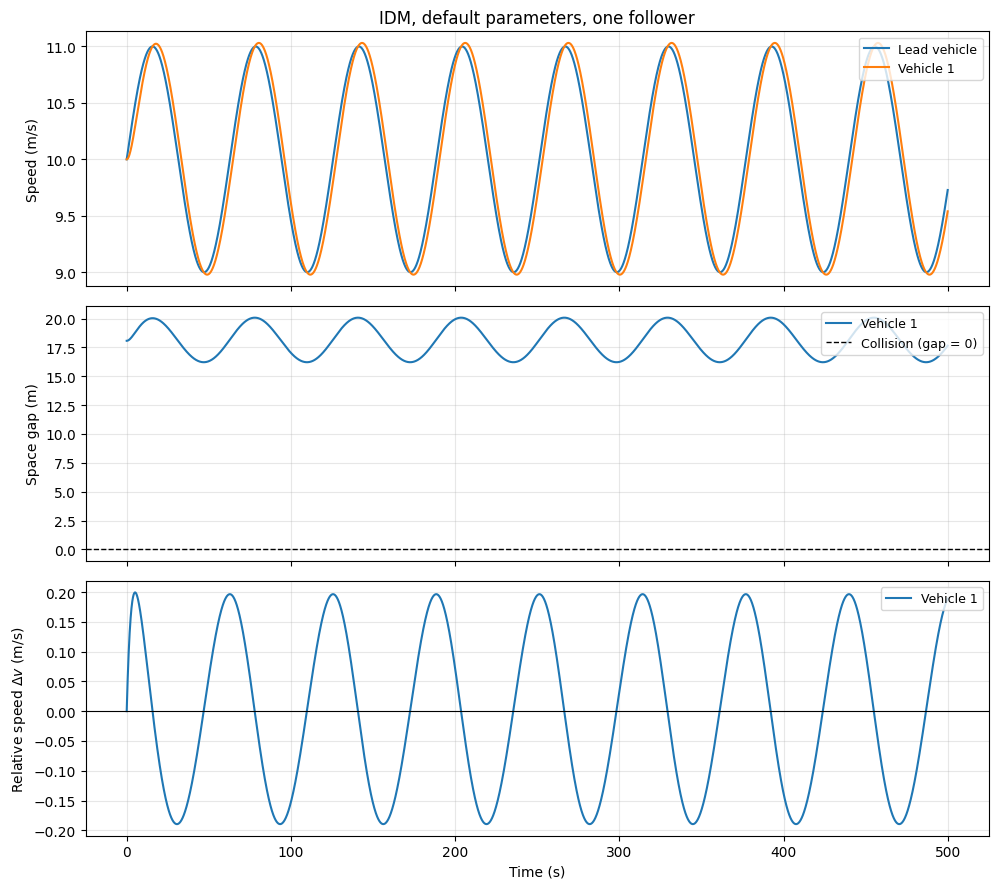

Gap: 16.2 to 20.1 m.   Ego speed: 9.0 to 11.0 m/s.


In [38]:
plot_cars(time_steps, [lead_speeds, ego_speeds], [space_gaps], 'IDM, default parameters, one follower')
print(f'Gap: {min(space_gaps):.1f} to {max(space_gaps):.1f} m.   Ego speed: {min(ego_speeds):.1f} to {max(ego_speeds):.1f} m/s.')

## 4 Multi-car

Car 0 is the lead vehicle, car 1 follows car 0, car 2 follows car 1, and so on. Nothing in the model changes: each follower runs the same loop, with the speed history of the car ahead as its `lead_speeds`. To simulate a longer platoon, change `num_following_vehicles`.

In [39]:
def simulate_platoon(time_steps, p, lead_speeds, num_following_vehicles=5,
                     initial_ego_speed=None, initial_space_gap=None):
    """Chain followers behind the lead vehicle. Returns lists indexed by vehicle (0 = lead)."""
    if initial_ego_speed is None:
        initial_ego_speed = lead_speeds[0]             # start every car at the leader's initial speed
    if initial_space_gap is None:
        initial_space_gap = equilibrium_gap(initial_ego_speed, p)
    all_speeds = [np.asarray(lead_speeds)]
    all_space_gaps = []
    current_lead_speeds = lead_speeds
    for i in range(1, num_following_vehicles + 1):
        _, gaps, speeds, _ = simulate_car_following(
            time_steps, p, initial_ego_speed, initial_space_gap, current_lead_speeds)
        all_speeds.append(np.asarray(speeds))
        all_space_gaps.append(np.asarray(gaps))
        current_lead_speeds = speeds                   # this car is the next car's leader
    return all_speeds, all_space_gaps

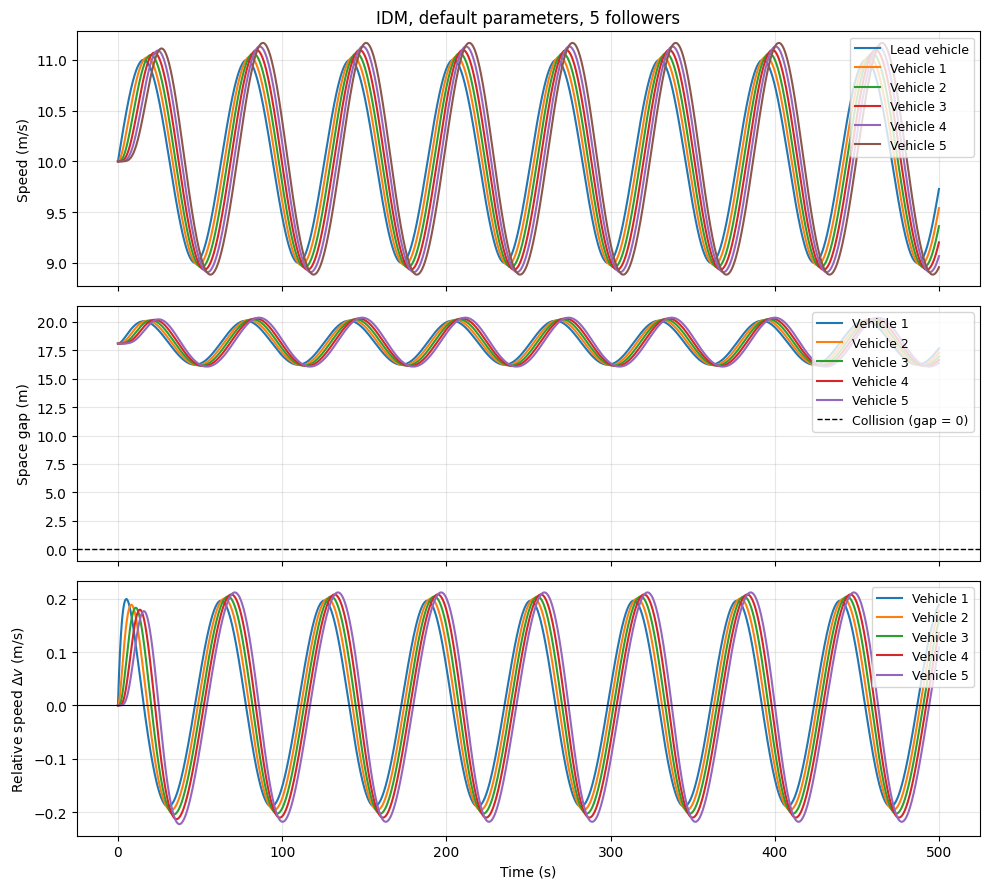

Vehicle 1: gap  16.2 to  20.1 m, speed  8.98 to 11.03 m/s
Vehicle 2: gap  16.2 to  20.1 m, speed  8.96 to 11.06 m/s
Vehicle 3: gap  16.1 to  20.2 m, speed  8.93 to 11.10 m/s
Vehicle 4: gap  16.1 to  20.3 m, speed  8.91 to 11.13 m/s
Vehicle 5: gap  16.1 to  20.3 m, speed  8.88 to 11.17 m/s


In [40]:
num_following_vehicles = 5
all_speeds, all_space_gaps = simulate_platoon(time_steps, idm_params, lead_speeds, num_following_vehicles)

plot_cars(time_steps, all_speeds, all_space_gaps, f'IDM, default parameters, {num_following_vehicles} followers')
for i, gaps in enumerate(all_space_gaps, start=1):
    print(f'Vehicle {i}: gap {gaps.min():5.1f} to {gaps.max():5.1f} m, speed {all_speeds[i].min():5.2f} to {all_speeds[i].max():5.2f} m/s')